In [ ]:
!pip install qiskit
!pip install qiskit-ibm-runtime
!pip install pylatexenc
!pip install qiskit[visualization] pylatexenc

from IPython.display import clear_output # ignore - just cleanup
clear_output() # ignore - just cleanup

In [ ]:
from os import name

import numpy as np
from matplotlib import pyplot as plt


from qiskit import QuantumCircuit, QuantumRegister, AncillaRegister, ClassicalRegister
from qiskit.quantum_info import Operator, Statevector, Kraus, SparsePauliOp
from qiskit.circuit.library import UnitaryGate

from qiskit.transpiler import generate_preset_pass_manager
from qiskit_ibm_runtime import QiskitRuntimeService
from qiskit_ibm_runtime import EstimatorOptions
from qiskit_ibm_runtime import EstimatorV2 as Estimator

In [ ]:
params = ["A", "f", "t", "tau", "phi"]
N_params = len(params)
resolution_list = [4]*N_params # assume uniform resolution for each param

q_wavelet_data = 0
qreg_wavelet_data_list = []
for param, resolution in zip(params, resolution_list):
    q_wavelet_data_single = int(np.ceil(np.log2(resolution)))
    q_wavelet_data += q_wavelet_data_single

    qreg_wavelet_data_single = QuantumRegister(q_wavelet_data_single, name=f"{param}")
    qreg_wavelet_data_list.append(qreg_wavelet_data_single)

q_ancilla = N_params # ancilla qubits used as controls for the walk operators
qreg_ancilla = AncillaRegister(q_ancilla, name="Walk")

In [ ]:
qc = QuantumCircuit(*qreg_wavelet_data_list, qreg_ancilla)

initial_statevector = np.zeros(2**q_wavelet_data)

A = 0
f = 0
t = 0
tau = 0
phi = 0
param_vals = [A, f, t, tau, phi]

bin_wavelet_data = ""
for param_val in param_vals:
    bin_wavelet_data += bin(param_val)[2:].zfill(q_wavelet_data_single) # assumes uniform resolution

bin_full = bin_wavelet_data # keep as a separate variable because we'll have other qubits later
dec_full = int(bin_full, 2)

print(A, f, t, tau, phi, bin_full)

initial_statevector[dec_full] = 1
# print(initial_statevector)

qc.initialize(initial_statevector, qreg_wavelet_data_list)

# THIS WILL PROBABLY TAKE 65 MILLION YEARS
# qc.draw("mpl")

0 0 0 0 0 0000000000


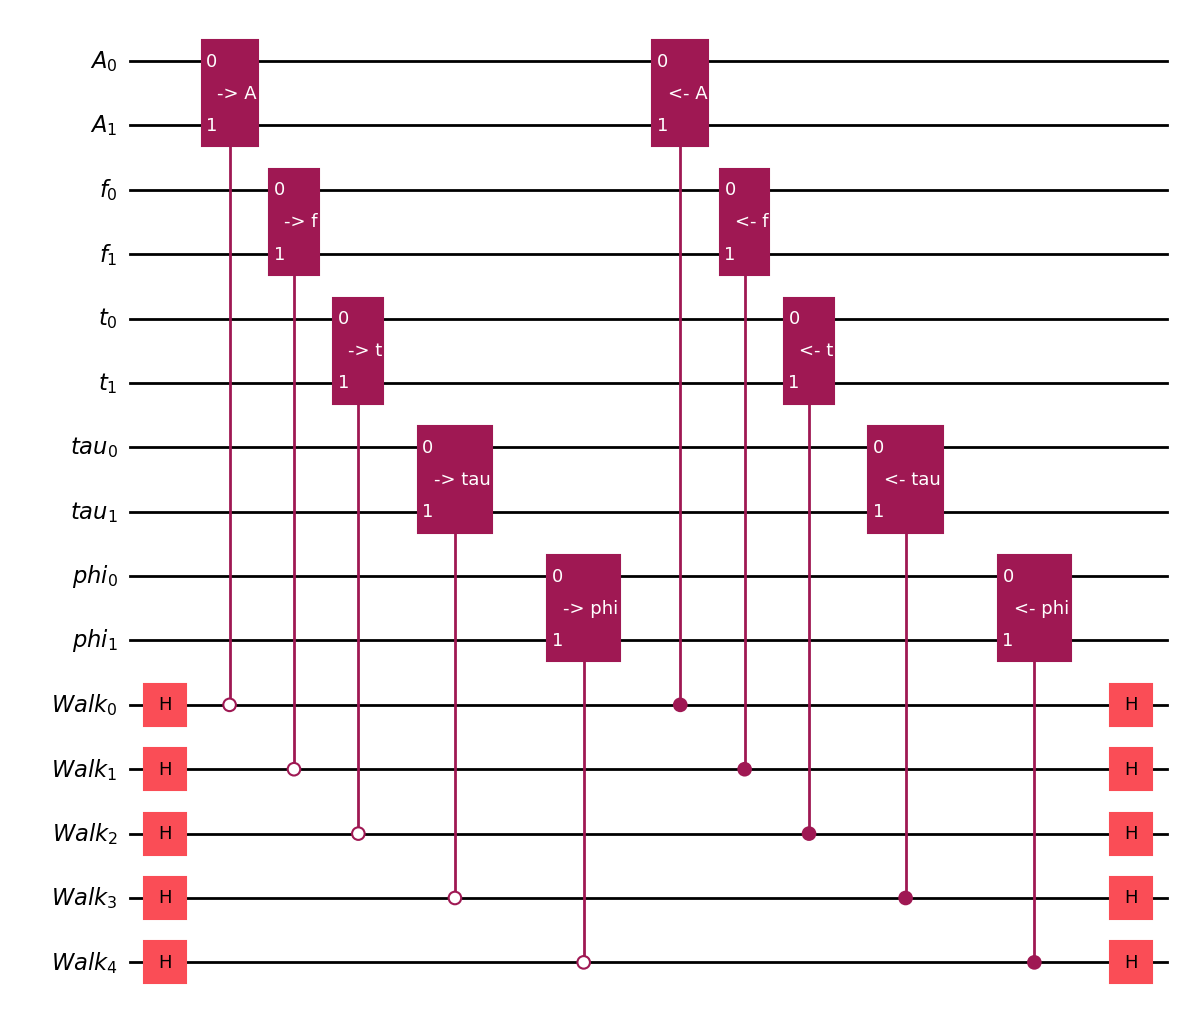

In [ ]:
up = Statevector([1,0])
down = Statevector([0,1])

velocity_list = [1, 2, 2, 2, 2]
M_list = []

for param, resolution, velocity in zip(params, resolution_list, velocity_list):
    D = 2**int(np.ceil(np.log2(resolution)))
    M = np.zeros((D, D))
    for i_init in range(D):
        i_final = i_init + velocity
        M[i_init][i_final % D] = 1
    M_list.append(M)

U_right_list = []
U_left_list = []
for param, M in zip(params, M_list):
    U = UnitaryGate(M, label=f"-> {param}")
    U_adj = UnitaryGate(M.conj().T, label=f"<- {param}")

    U_right = U.control(1, ctrl_state=0)
    U_right_list.append(U_right)

    U_left = U_adj.control(1, ctrl_state=1)
    U_left_list.append(U_left)

qc_timestep = QuantumCircuit(*qreg_wavelet_data_list, qreg_ancilla, name="Walk")

qc_timestep.h(qreg_ancilla)

for p, (param, qreg_wavelet_data_param, qubit_ancilla) in enumerate(zip(params, qreg_wavelet_data_list, qreg_ancilla)):
    qc_timestep.append(U_right_list[p], [qubit_ancilla, *qreg_wavelet_data_param])
    qc_timestep.append(U_left_list[p], [qubit_ancilla, *qreg_wavelet_data_param])

qc_timestep.h(qreg_ancilla)

qc_timestep.draw(output="mpl")

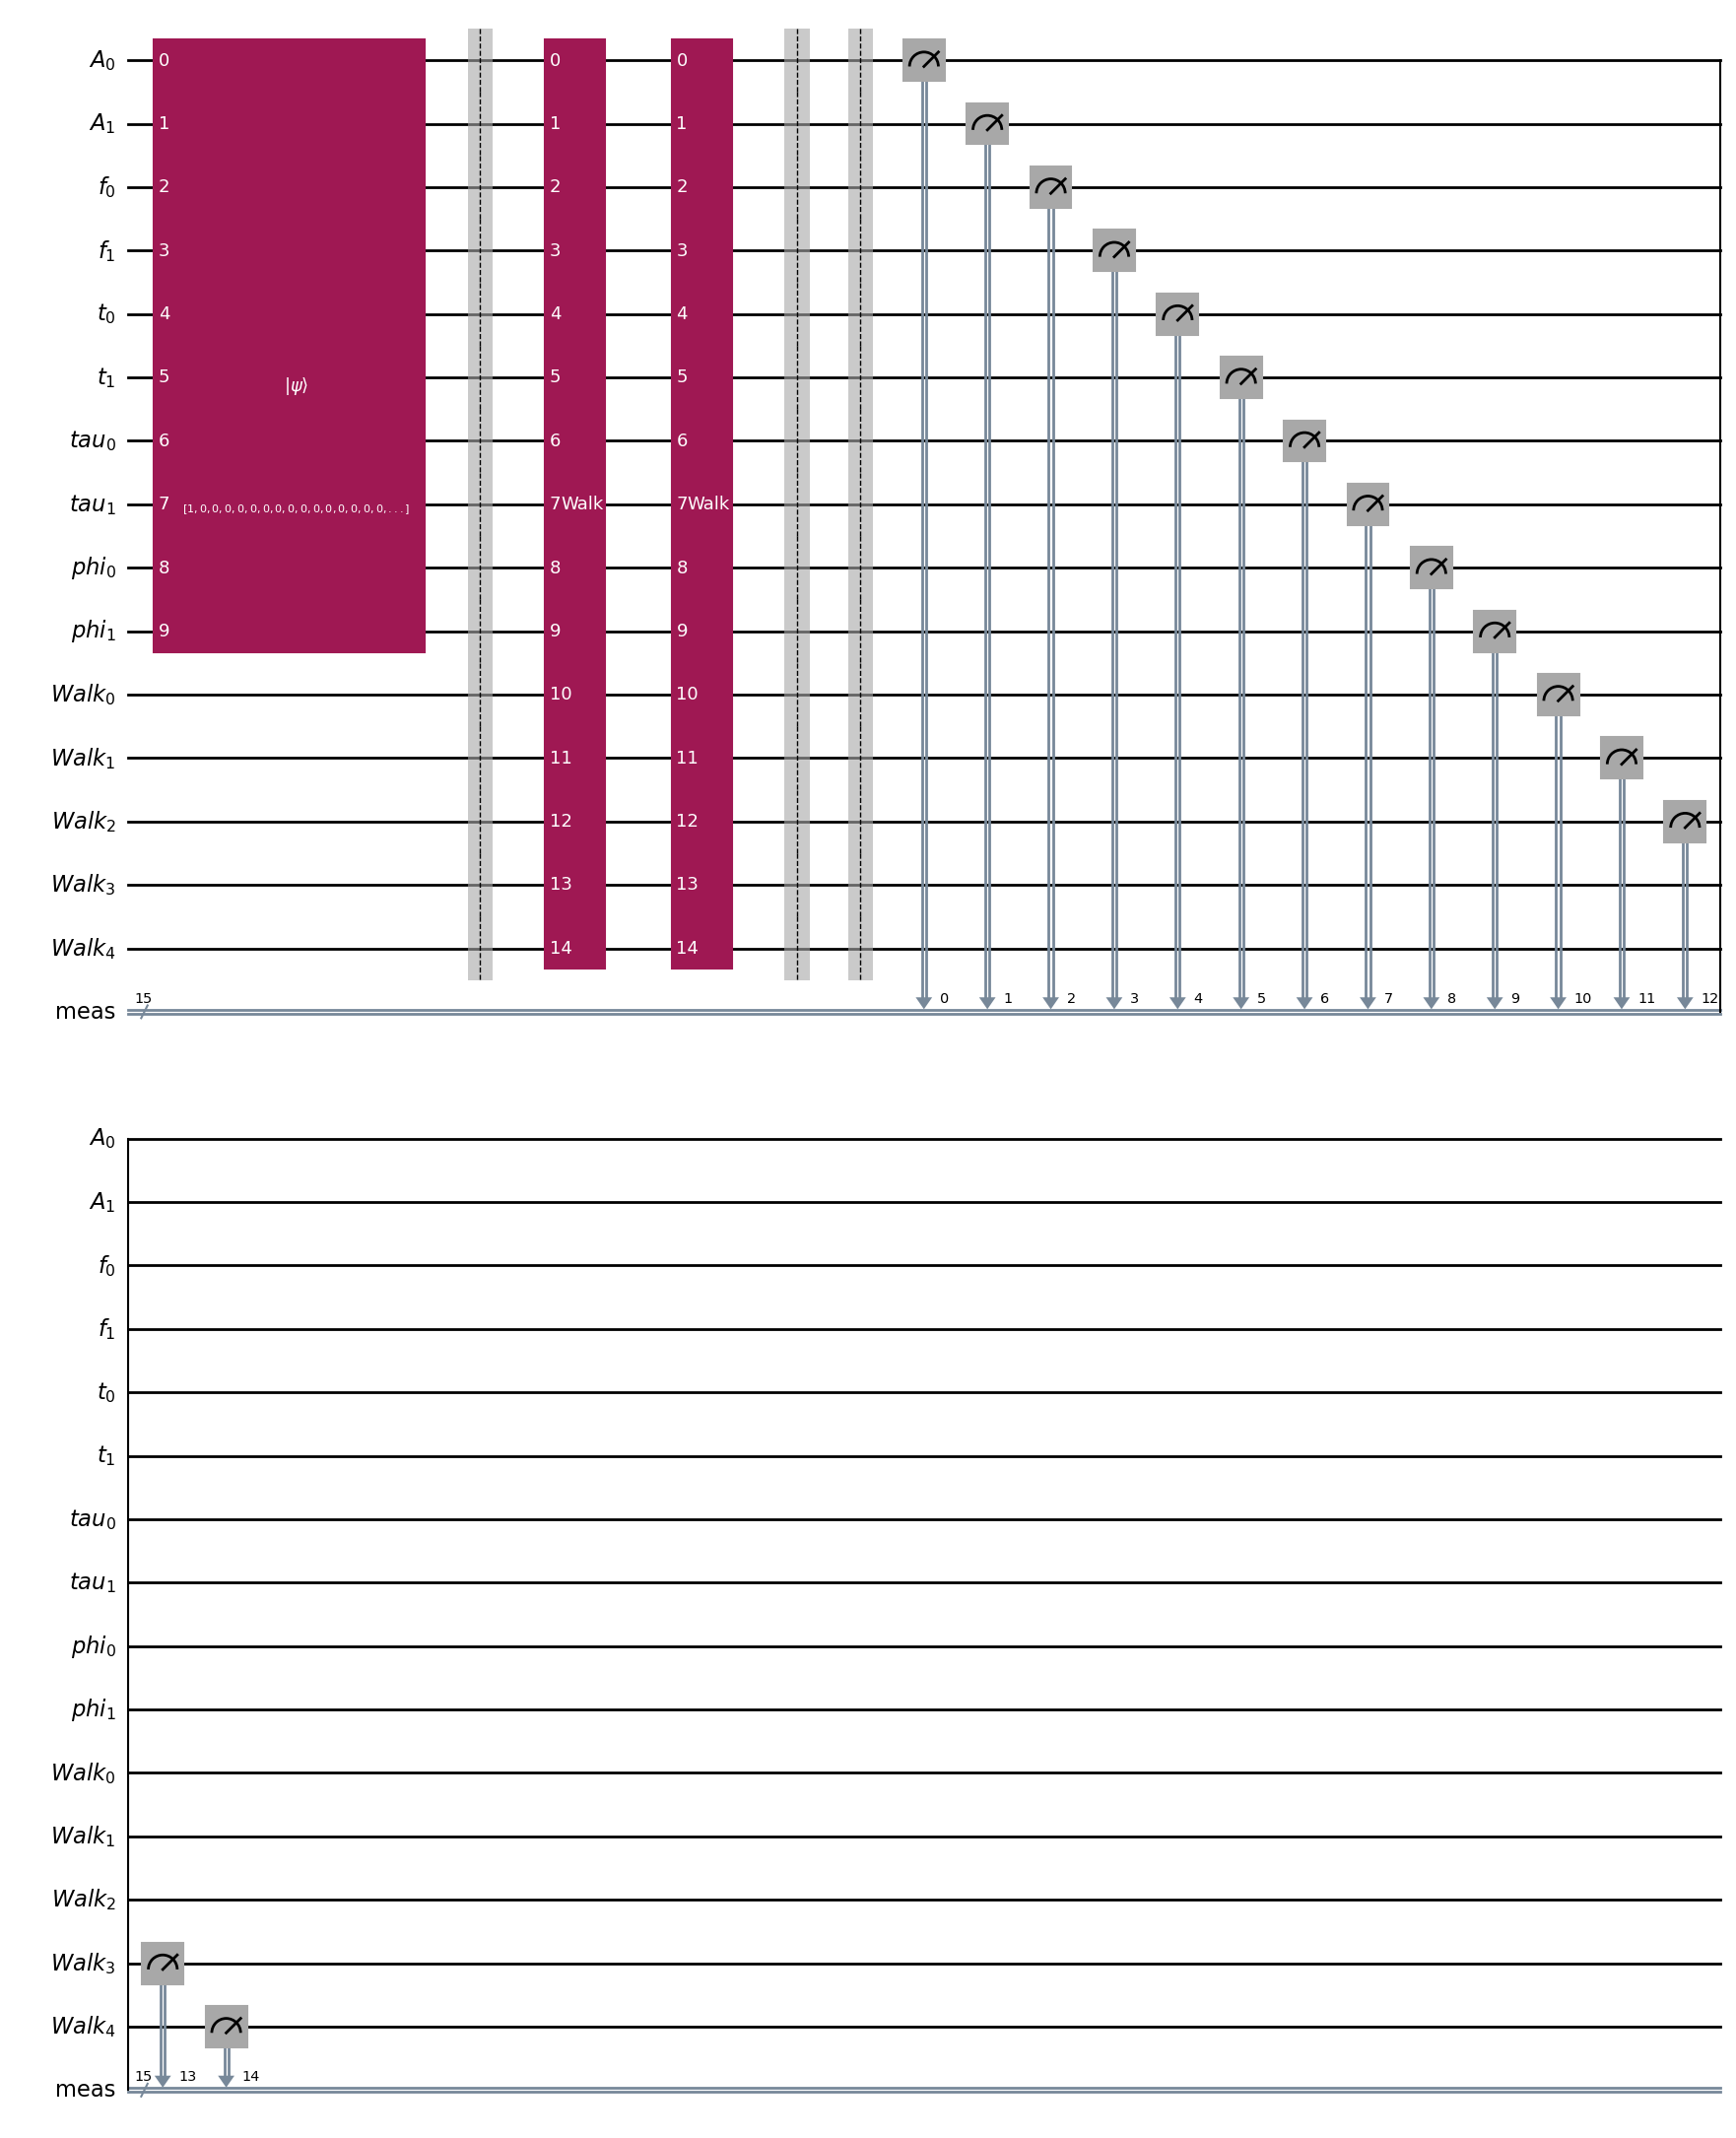

In [ ]:
t_0 = 2

qc = QuantumCircuit(*qreg_wavelet_data_list, qreg_ancilla)

qc.initialize(initial_statevector, qreg_wavelet_data_list)

qc.barrier()

for _ in range(2):
    qc.append(qc_timestep, range(q_wavelet_data + q_ancilla))

qc.barrier()

qc.measure_all()

qc.decompose(reps=0).draw(output="mpl")